## Intro

_Amnesia: The Dark Descent_ remains one of the most popular and influential titles of 2010s among both horror games community and Youtube Letsplayer community, in particular contributing greatly to the launch of the careers of such icons of the Letsplay genre as Pewdiepie and Markiplier as well as revitalising the concept of a so-called "walking simulator" subgenre of horror. _Dark Descent_'s success was caused by, among other things, the developers providing an official, relatively accessible level editor and support for the custom campaigns created in - so-called "custom stories" very early on in the lifetime of the game, spawning an active modding community and encouraging, with time, the creation of original adventures on the game's engine that had provided the expierence rivaling the one of vanilla _Dark Descent_, its official _Justine_ DLC, or even the later sequels such as _Amnesia: The Machine for Pigs_.

Since the _Dark Descent_'s release in 2010, more than a thousand custom stories for it were created, alongside other types of mods. While the mods vary greatly in quality, a lot of them have enough care and originality put into them to have a cultural value comparable to that of a full-fledged indie game. As the _Dark Descent_ playerbase had aged, the need for archiving and cataloguing the mods have arised.

## 1. Fetching, cleaning, and descriptive analysis of the Sanitarium's data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from custom_parsers import parse_sanitarium

#df = parse_sanitarium('https://wrecx.github.io/tms/')
#df.head()

In [2]:
#df.info()

Let's make the reserve copy of the fetched data right away to not have to scrape it again in case of the unexpected problems arising down the line. Take note

In [3]:
#Some of the values in the data may be blank (empty strings), which would be rendered as missing values if saved as csv file with default parametres and read again later.
#To avoid this (for reproducibility of the code below no matter if the data is re-parsed from Mod Sanitarium again or loaded from csv file), na_rep='____' parameter was used.
#df.to_csv('scraped_data/sanitarium_data.csv', na_rep='____')
df = pd.read_csv('scraped_data/sanitarium_data.csv', index_col='index')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1355 entries, 1 to 1355
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   title     1355 non-null   str  
 1   author    1355 non-null   str  
 2   released  1355 non-null   str  
 3   type      1355 non-null   str  
 4   url       1355 non-null   str  
dtypes: str(5)
memory usage: 53.1 KB


The dataset describes more than 13 hundreds mods with five properties: title, author, release date, mod type and the web address to where it can be downloaded from. While there are no explicit missing values in the data, the way in which the __**parse_sanitarium**__ function works could have let in "slient" missing values such as an empty string in place of the author's name or the download url, or the incomplete release date. Such potential missing values in the release date, mod type, and download url fields would be handled shortly below while the ones in the author and title fields would be ignored - for this analysis purposes, a few mistakes in them pose no threat to the data integrity.

The column **type** describes the title of the mod. Mod Sanitarium classifies __Dark Descent__ mods into three categories:

* Custom Story - a custom campaign accessible from a selection window inside a dedicated submenu of the game's main menu. May consist of one or a multitude custom levels connected with each other, usually following a linear gameplay/puzzle progression.

* Full Conversion mod (FC) - a more "high effort" mod that is launched from its own executable file, unlike custom stories. Practically always consists of multiple levels and usually has much more custom content (such as storyline, voice acting, or 3D models) than a custom story.

* Addon - a "normal" mod that alters the gameplay, visuals, or rarely some technical aspects of the game and affects both the original levels of __Dark Descent__ and those of custom stories (and sometimes full conversions) installed, but is not a playable expierence by itself. Alternatively, an asset pack that can only be used for the creation of other mods.

Let's look at how much of the each type of mod we have:

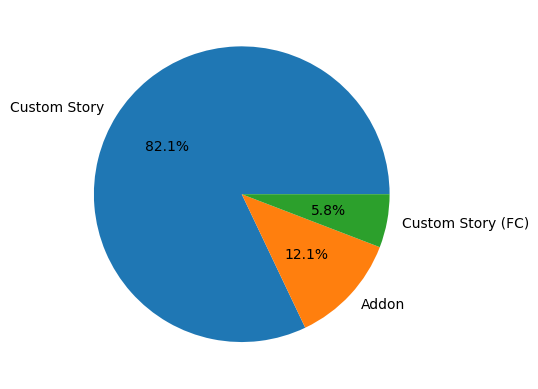

In [4]:
fig, ax = plt.subplots()
fracs = df['type'].value_counts()
labels = fracs.keys()

ax.pie(fracs, labels=labels, autopct='%1.1f%%')

plt.show()

What we see is about to be expected: the overwhelming majority - more than 82% - of the mods is made by the custom stories, most likely due to the relative ease of their creation compared to the full conversion mods and the much higher player demand compared to addons.

The focus of this project is on the playable mods - custom stories and full conversions. However, the data about the addons would not be discarded immediatedly - their relatively small proportion is unlikely to skew the following descriptive analysis noticeably, and the additional data parsed on them may be used by someone else in the future.

Now let's look at what would be the crucially important information for getting the more data on mods - the places where they are hosted.

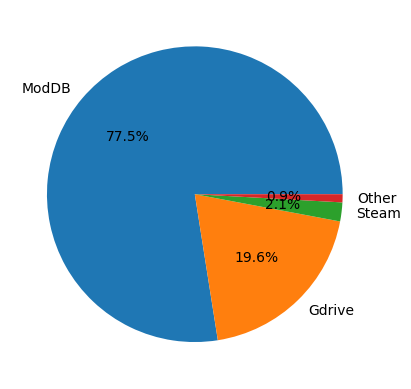

In [5]:
def get_mod_source(url):
    if 'moddb' in url:
        return 'ModDB'
    elif 'steam' in url: 
        return 'Steam'
    elif 'drive' in url:
        return 'Gdrive'
    else:
        return 'Other'

df['mod source'] = df['url'].apply(get_mod_source)

fig, ax = plt.subplots()
fracs = df['mod source'].value_counts()
labels = fracs.keys()

ax.pie(fracs, labels=labels, autopct='%1.1f%%')

plt.show()

**Mod source thoughts**

In [6]:
obscure_source_mods = df[(df['mod source']=='Steam')|(df['mod source']=='Other')][['title', 'url']]
print(f'There are {obscure_source_mods.shape[0]} mods posted or only preserved in obscure places.')

There are 40 mods posted or only preserved in obscure places.


In [7]:
#obscure_source_mods.to_csv('scraped_data/other_sources.csv')

In [8]:
non_moddb_addons = df[(df['mod source']!='ModDB')&(df['type']!='Custom Story')]
print(f'Only {non_moddb_addons.shape[0]} FCs or addons are hosted not on ModDB.')

Only 5 FCs or addons are hosted not on ModDB.


In [9]:
non_moddb_addons.head()

,title,author,released,type,url,mod source
index,,,,,,
35,Trapped in Broadmoor,Scarily Olivia,2024-08-28,Custom Story (FC),https://steamcommunity.com/sharedfiles/filedet...,Steam
105,House of Retards,Wrecx,2022-02-21,Custom Story (FC),https://drive.google.com/file/d/1wErSvvbfG4nTL...,Gdrive
115,Ancient Showdown,LivajQ,2022-01-17,Custom Story (FC),https://drive.google.com/file/d/1nYCIXYyK3uBSr...,Gdrive
527,Polaris,Kalaallit-Games,2014-09-30,Custom Story (FC),https://drive.google.com/file/d/1cxaYyZqa2x0FU...,Gdrive
1203,LightingEngine,???,2011-12-04,Addon,https://drive.google.com/file/d/1Ho5yfseIyBjVq...,Gdrive


In [10]:
import re

def sanitize_filename(filename: str, replacement: str = "") -> str:
    forbidden_chars = r'[\\/:*?"<>|]'
    return re.sub(forbidden_chars, replacement, filename)

df['title'] = df['title'].apply(sanitize_filename)

In [11]:
title_words = []

def title_word_bag(string):
    word_list = string.lower().split(sep=' ')
    word_list = [word for word in word_list if len(word)>3]
    title_words.extend(word_list)
    return None

df['title'].apply(title_word_bag)
title_words = pd.Series(title_words).value_counts().reset_index()
title_words.columns = ['word', 'count']
title_words.head(20)

,word,count
0,house,57
1,escape,46
2,dark,44
3,castle,42
4,chapter,42
5,amnesia,41
6,mansion,29
7,nightmare,28
8,story,26
9,menu,23


In [12]:
df['title length'] = df['title'].apply(lambda s: len(s))

print(f'The average title of the mod is {round(df['title length'].median())} characters long.')

The average title of the mod is 16 characters long.


In [13]:
shortest_names = df[df['title length']<4]
shortest_names.head(10)

,title,author,released,type,url,mod source,title length
index,,,,,,,
109,HE,Nunrtevy,2022-02-12,Custom Story,https://www.moddb.com/games/amnesia-the-dark-d...,ModDB,2
121,Bus,Daniel5784,2021-11-01,Addon,https://www.moddb.com/mods/na1635700599/downlo...,ModDB,3
334,SDP,Darkfires,2018-09-30,Custom Story,https://www.moddb.com/mods/sdp/downloads/sdp,ModDB,3
944,GTB,Kiralmmortal,2012-07-16,Custom Story,https://www.moddb.com/mods/gtb/downloads/gtb-v10,ModDB,3
1126,Me,Joker1ruler,2012-02-22,Custom Story,https://www.moddb.com/mods/me/downloads/me-v12,ModDB,2
1270,Hay,Nkmol,2011-07-25,Addon,https://www.moddb.com/games/amnesia-the-dark-d...,ModDB,3


In [14]:
longest_names = df[df['title length']>45]
longest_names.head(20)

,title,author,released,type,url,mod source,title length
index,,,,,,,
94,The Search of the Unique Flashlight - Reimagined,Wrecx,2022-08-14,Custom Story (FC),https://www.moddb.com/mods/the-search-of-the-u...,ModDB,48
412,Upheaval The Darkness Ascension of Whisperstream,ShiaadowinskyXlash,2016-11-15,Custom Story,https://www.moddb.com/mods/upheaval-the-darkne...,ModDB,48
435,Painful Reality - Interval 03 - End of the circle,TeeZaah,2016-06-04,Custom Story,https://www.moddb.com/mods/painful-reality-int...,ModDB,49
443,Painful Reality - Interval 02 - Unexpected visit,TeeZaah,2016-02-09,Custom Story,https://www.moddb.com/mods/painful-reality-int...,ModDB,48
567,The Call From Another Dimension 2 Herman's Rev...,MatiaSikaGames,2014-04-03,Custom Story,https://www.moddb.com/mods/the-call-from-anoth...,ModDB,50
681,The Dark Treasure - Credel Castle's Untold Story,Kreaturet,2013-08-09,Custom Story,https://www.moddb.com/mods/the-dark-treasure-c...,ModDB,48
964,Resident Evil (it needs a password to extract it),???,2012-06-25,Custom Story,https://drive.google.com/file/d/13qrljbNTQi818...,Gdrive,49
1025,"Atrapados en la Mente, Capitulo 1 Las Ruinas d...",Skirnks017,2012-05-12,Custom Story,https://www.moddb.com/mods/amnesia-project-old...,ModDB,52
1104,Palistov's Holiday Series - St. Patrick's Day ...,Timorem,2012-03-15,Custom Story,https://www.moddb.com/mods/palistovs-holiday-s...,ModDB,50


**Start dates section**

In [15]:
from datetime import datetime

err_dates = []

def is_invalid_iso_date(s):
    try:
        datetime.strptime(s, "%Y-%m-%d")
        return False
    except ValueError:
        err_dates.append(s)
        return True
    
err_dates_count = sum(df['released'].apply(is_invalid_iso_date))
print(f'There are {err_dates_count} mods with missing or incomplete release dates.')

There are 15 mods with missing or incomplete release dates.


In [16]:
print(err_dates)

['2021-05', '2018', '2016', '2015-10', '2014', '2013', '2012', '2012', '2011', '0000', '0000', '0000', '0000', '0000', '0000']


In [17]:
def parse_date(s):
    try:
        return datetime.strptime(s, "%Y-%m-%d")
    except ValueError:
        if '-' in s:
            s = s + '-16'
        elif s != '0000':
            s = s + '-06-30'
        else:
            s = "2010-09-08"
        return datetime.strptime(s, "%Y-%m-%d")
        
df['released'] = df['released'].apply(parse_date)

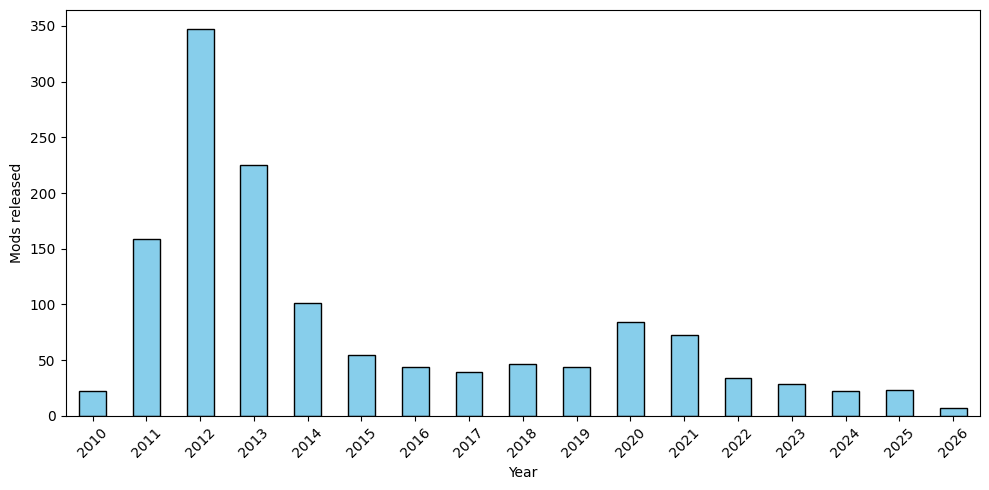

In [18]:
plt.figure(figsize=(10, 5))
mods_per_year = df['released'].dt.year.value_counts().sort_index()
mods_per_year.plot(kind='bar', color='skyblue', edgecolor='black')

plt.xlabel('Year')
plt.ylabel('Mods released')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [19]:
print(f'There are {df['author'].nunique()} unique author tags in Sanitarium.')

There are 831 unique author tags in Sanitarium.


In [20]:
from custom_parsers import name_formatter, get_nickname

df['author nickname'] = df['author'].apply(get_nickname)
print(f'There are {df['author nickname'].nunique()} authors who had used nicknames.')

There are 5 authors who had used nicknames.


In [21]:
nicknamed_authors = df[~(df['author nickname'].isna())][['author', 'author nickname']]
nicknamed_authors.head(10)

,author,author nickname
index,,
214,Under The Keyboard Mods (UTKM),utkm
923,Vitor Frias (Vyzer),vyzer
969,Vitor Frias (Vyzer),vyzer
1035,Jussi (Unearthlybrutal),unearthlybrutal
1286,MyPetCreeper (Jack),jack
1355,victorkim890(KimmyChimmy),kimmychimmy


In [22]:
nickname_mapping = {'utkm': 'underthekeyboardmods', 'vyzer': 'vitorfrias', 'unearthlyburial':'jussi', 'jack':'mypetcreeper', 'kimmychimmy':'victorkim890'}
df['author'] = df['author'].apply(name_formatter).apply(lambda s: nickname_mapping(s) if s in nickname_mapping.keys() else s)
df = df.drop(labels=['author nickname'], axis=1)
print(f'There are {df['author'].nunique()} unique mod authors.')

There are 818 unique mod authors.


In [23]:
author_count = df['author'].value_counts()

print(f'The typical author had produced {int(author_count.median())} mods.')

The typical author had produced 1 mods.


In [24]:
author_count = author_count.reset_index()
author_count.columns = ['author', 'mods made']
author_count.head(20)

,author,mods made
0,wrecx,23
1,kiralmmortal,23
2,skashi,20
3,xarox02,17
4,oddstuff,15
5,sabatu,13
6,karelkupec475,13
7,meeeeeerk,9
8,umbakarna,9
9,nkmol,9


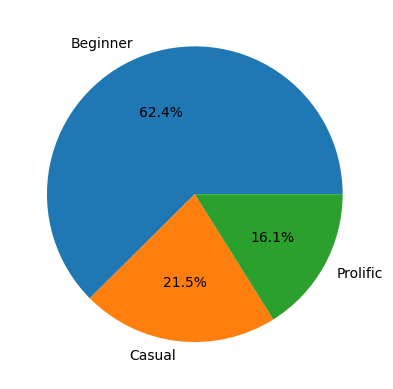

In [25]:
def get_author_rank(num):
    if num<3:
        return 'Beginner'
    elif num<7:
        return 'Casual'
    else:
        return 'Prolific'

author_count = df['author'].value_counts()
df['author rank'] = df['author'].apply(lambda s: author_count[s]).apply(get_author_rank)

fig, ax = plt.subplots()
fracs = df['author rank'].value_counts()
labels = fracs.keys()

ax.pie(fracs, labels=labels, autopct='%1.1f%%')

plt.show()

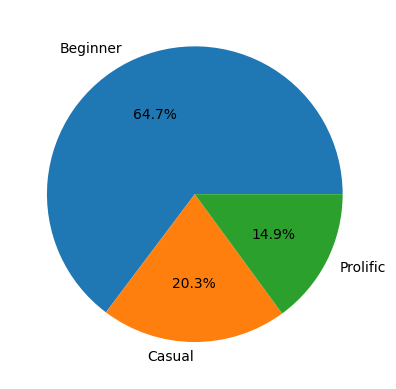

In [26]:
story_mods_only = df[df['type']!='Addon']
story_mods_only_author_count = story_mods_only['author'].value_counts()
story_mods_only['author rank'] = story_mods_only['author'].apply(lambda s: author_count[s]).apply(get_author_rank)

fig, ax = plt.subplots()
fracs = story_mods_only['author rank'].value_counts()
labels = fracs.keys()

ax.pie(fracs, labels=labels, autopct='%1.1f%%')

plt.show()

In [27]:
story_mods_only_author_count = story_mods_only_author_count.reset_index()
story_mods_only_author_count.columns = ['author', 'mods made']
story_mods_only_author_count.head(20)

,author,mods made
0,wrecx,23
1,skashi,20
2,sabatu,13
3,karelkupec475,13
4,kiralmmortal,12
5,oddstuff,12
6,xarox02,10
7,cheesydeveloper,8
8,teezaah,8
9,flawlesshappiness,8


In [28]:
author_spans = df.groupby('author')['released'].agg(['min', 'max'])

author_spans['active for'] = author_spans['max'] - author_spans['min']

longest_active_author = author_spans['active for'].idxmax()
max_span = author_spans['active for'].max()

print(f"Author {longest_active_author} had been creating Amnesia mods for more than {max_span.days // 365} years.")

Author apjjm had been creating Amnesia mods for more than 14 years.


In [29]:
df[df['author']=='apjjm'].head()

,title,author,released,type,url,mod source,title length,author rank
index,,,,,,,,
22,Teamnesia - Platform Perils -,apjjm,2025-07-21,Custom Story,https://drive.google.com/file/d/1ghN-wKSFxAj4v...,Gdrive,29,Beginner
1308,Tetris - The Dark Descent -,apjjm,2011-04-22,Custom Story,https://www.moddb.com/mods/tetris-the-dark-des...,ModDB,27,Beginner


In [30]:
rank_mapping = {'Beginner': 0, 'Casual': 1, 'Prolific': 2}
df['author rank'] = df['author rank'].apply(lambda s: rank_mapping[s])
df = df.drop(labels=['author', 'mod source'], axis=1)

mod_type_mapping = {'Addon': -1, 'Custom Story': 0, 'Custom Story (FC)': 1}
addons_only = df[df['type']=='Addon']
df['type'] = df['type'].apply(lambda s: mod_type_mapping[s])

## 2. Collecting the new data and using it to enrich the dataset.

**Describing the parsing process**

In [31]:
from custom_parsers import get_moddb_data, parse_urls_to_csv_vectorized

#parse_urls_to_csv_vectorized(df['url'], 'scraped_data/moddb_data.csv', "url;download url;archive size;moddb downloads\n", get_moddb_data, 3, None)

In [32]:
moddb_data = pd.read_csv('scraped_data/moddb_data.csv', sep=';')
moddb_data.sample(10)

,url,download url,archive size,moddb downloads
1227,https://www.moddb.com/games/amnesia-the-dark-d...,https://www.moddb.com/addons/start/36761,1.06mb,802
1075,https://www.moddb.com/mods/amnesia-project-old...,https://www.moddb.com/downloads/start/210237,53.21mb,140
1328,https://forum.frictionalgames.com/thread-6058....,NaN,NaN,NaN
1319,https://www.moddb.com/mods/the-estate/download...,https://www.moddb.com/downloads/start/30827,5.37mb,"10,697"
1269,https://drive.google.com/file/d/1eJ38YXnuVG0pH...,NaN,NaN,NaN
1237,https://www.moddb.com/mods/quiet/downloads/cha...,https://www.moddb.com/downloads/start/36430,27.12mb,"11,608"
680,https://www.moddb.com/mods/the-dark-treasure-c...,https://www.moddb.com/downloads/start/58070,140.58mb,"4,837"
515,https://drive.google.com/file/d/1PZmI9WeQL_gsO...,NaN,NaN,NaN
872,https://drive.google.com/file/d/1iu7qqam4Rk4_E...,NaN,NaN,NaN
1051,https://drive.google.com/file/d/1Nh63FY5eLJpen...,NaN,NaN,NaN


In [33]:
df = pd.merge(left=df, right=moddb_data, how='left', on='url')
df.sample(10)

,title,released,type,url,title length,author rank,download url,archive size,moddb downloads
201,House of Creep 8 (fan made),2020-10-31,0,https://www.moddb.com/mods/house-of-creep-8-fa...,27,1,https://www.moddb.com/downloads/start/203194,148.55mb,476
1119,The Haunted Stairwell,2012-02-26,0,https://www.moddb.com/mods/the-haunted-stairwe...,21,0,https://www.moddb.com/downloads/start/40773,1.2mb,"7,871"
983,Revenge,2012-06-16,0,https://drive.google.com/file/d/1nP-GH0CCT09UX...,7,0,NaN,NaN,NaN
564,Paranoia,2014-04-08,0,https://www.moddb.com/groups/amnesia-modders/d...,8,0,https://www.moddb.com/downloads/start/67983,10.64kb,135
1285,Jacks Survival,2011-06-16,0,https://drive.google.com/file/d/167MjdRExyvpae...,14,0,NaN,NaN,NaN
1292,Test,2011-06-01,0,https://drive.google.com/file/d/1CDXWKvEmeiJSv...,4,1,NaN,NaN,NaN
1278,Isle,2011-07-04,0,https://drive.google.com/file/d/10nQEGrC6bZ9mJ...,4,1,NaN,NaN,NaN
998,Choice,2012-06-02,0,https://www.moddb.com/mods/shulle/addons/choice,6,0,https://www.moddb.com/addons/start/43534,11.02mb,"3,357"
429,Amnesia nightmare engine,2016-06-29,-1,https://www.moddb.com/mods/amnesia-nightmare-e...,24,0,https://www.moddb.com/downloads/start/106025,370.66kb,"1,148"
501,The Subconscious Trials,2014-12-31,0,https://www.moddb.com/mods/the-subconscious-tr...,23,0,https://www.moddb.com/downloads/start/78940,610.67mb,"3,601"


In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1355 entries, 0 to 1354
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   title            1355 non-null   str           
 1   released         1355 non-null   datetime64[us]
 2   type             1355 non-null   int64         
 3   url              1355 non-null   str           
 4   title length     1355 non-null   int64         
 5   author rank      1355 non-null   int64         
 6   download url     1039 non-null   str           
 7   archive size     1044 non-null   str           
 8   moddb downloads  1039 non-null   str           
dtypes: datetime64[us](1), int64(3), str(5)
memory usage: 95.4 KB


In [35]:
df['download url'] = df['download url'].fillna(value=df['url'])

In [36]:
def parse_numeral(string):
    try:
        return int(string.replace(',', ''))
    except AttributeError or ValueError:
        return None

df['moddb downloads'] = df['moddb downloads'].apply(parse_numeral)

print(f'The typical custom story had been downloaded from ModDB {round(df[df['type']==0]['moddb downloads'].median())} times.')
print(f'The typical full conversion had been downloaded from ModDB {round(df[df['type']==1]['moddb downloads'].median())} times.')
print(f'The typical addon had been downloaded from ModDB {round(df[df['type']==(-1)]['moddb downloads'].median())} times.')

The typical custom story had been downloaded from ModDB 1034 times.
The typical full conversion had been downloaded from ModDB 897 times.
The typical addon had been downloaded from ModDB 191 times.


In [37]:
def standartise_file_size(string):
    try:
        string = string.lower()
        numeral = string[:-2]
        units = string[-2:]
        if units=='kb':
            result = float(numeral) / 1024
        elif units=='mb':
            result = float(numeral)
        elif units=='gb':
            result = float(numeral) * 1024
        else:
            return None
        return round(result, 2)
    except AttributeError:
        return None

df['archive size'] = df['archive size'].apply(standartise_file_size)

print(f'The typical custom story is about {df[df['type']==0]['archive size'].median():.2f} MB in size when archived.')
print(f'The typical full conversion is about {df[df['type']==1]['archive size'].median():.2f} MB in size when archived.')
print(f'The typical addon is about {df[df['type']==(-1)]['archive size'].median():.2f} MB in size when archived.')

The typical custom story is about 14.07 MB in size when archived.
The typical full conversion is about 311.31 MB in size when archived.
The typical addon is about 2.33 MB in size when archived.


In [38]:
large_mods = df[df['archive size'] >= 100]
print(f'There are {large_mods.shape[0]} huge mods.')

There are 224 huge mods.


In [39]:
very_large_mods = df[df['archive size'] >= 500]
print(f'There are {very_large_mods.shape[0]} very huge mods.')

There are 72 very huge mods.


In [40]:
df_download = df[(df['archive size'] < 500)|(df['archive size'].isna())].sort_values(by='archive size', axis=0, ascending=True, na_position='first', ignore_index=True)[:800]

In [41]:
from custom_parsers import download_gdrive_mod, download_moddb_mod
import os

storage_directory = "E:\\Amnesia mods"

def download_any_mod(url, name, wait_time, storage_dir):
    for suffix in ['.zip', '.rar', '.7z']:
        download_path = os.path.join(storage_dir, name+suffix)
        if os.path.exists(download_path):
            return None
    if 'moddb' in url and 'start' in url:
        return download_moddb_mod(url, name, wait_time, storage_dir)
    elif 'drive' in url:
        return download_gdrive_mod(url, name, wait_time, storage_dir)
    else:
        return None

In [42]:
from concurrent.futures import ThreadPoolExecutor
'''
download_tasks = list(zip(df_download['download url'], df_download['title']))
with ThreadPoolExecutor(max_workers=4) as executor:
    executor.map(lambda task: download_any_mod(task[0], task[1], 15, storage_directory), download_tasks)
'''

"\ndownload_tasks = list(zip(df_download['download url'], df_download['title']))\nwith ThreadPoolExecutor(max_workers=4) as executor:\n    executor.map(lambda task: download_any_mod(task[0], task[1], 15, storage_directory), download_tasks)\n"

In [43]:
import os

downloaded_files = pd.Series(os.listdir(storage_directory)).apply(lambda s: '.'.join(s.split(sep='.')[0:-1]))
not_downloaded = df_download['title'].apply(lambda s: s if s not in downloaded_files.values else None).dropna(axis=0)
not_downloaded.shape[0]

59

In [44]:
not_downloaded

1                              Zoofy's Compact Inventory
10                                             The Greed
13                                    The Abandoned Base
16                        Sclerosis an Amnesia VR remake
37                            Retextured Entities Pack 1
38                                        Badcats Carpet
41                                       Escape manson 3
43                                      Escape battle xd
51                                       Escape manson 2
55                                      Danels Christmas
64                                      A Fathers Secret
69                                     When I am no more
70                                      Alchemyst's Rush
75                            Turn Back Time Chapter 1-5
76                                          Csendes Domb
81                  Castle of the Living Dead A New Evil
99                                        Where is Isaac
117                            

In [45]:
#not_downloaded.to_json('scraped-data/failed_downloads.json')

In [46]:
'''
from custom_parsers import parse_titles_to_csv_vectorized, analyse_mod_archive

df_download = df_download[df_download['title'].isin(downloaded_files)]
header = "title;archive size true;full size;map count;description;ingame text lines;title screen;custom models;custom sounds"

parse_titles_to_csv_vectorized(df_download['title'], "scraped_data/epic_scraping_data.csv", header, analyse_mod_archive, 8, storage_directory)
'''

'\nfrom custom_parsers import parse_titles_to_csv_vectorized, analyse_mod_archive\n\ndf_download = df_download[df_download[\'title\'].isin(downloaded_files)]\nheader = "title;archive size true;full size;map count;description;ingame text lines;title screen;custom models;custom sounds"\n\nparse_titles_to_csv_vectorized(df_download[\'title\'], "scraped_data/epic_scraping_data.csv", header, analyse_mod_archive, 8, storage_directory)\n'

In [47]:
processed_mod_data = pd.read_csv("scraped_data/epic_scraping_data.csv", sep=",")
cols = ['title', 'released', 'type', 'url', 'title length', 'author rank', 'archive size', 'moddb downloads', 
        'archive size true', 'full size', 'map count', 'description', 'ingame text lines', 'title screen', 'custom models', 'custom sounds']

df = df.merge(processed_mod_data, how='left', on="title")[cols]
df.info()

C:\Users\New\AppData\Local\Temp\ipykernel_7076\2988265575.py:1: DtypeWarning: Columns (0: archive size true, 1: map count, 2: Unnamed: 103, 3: Unnamed: 104, 4: Unnamed: 105, 5: Unnamed: 106, 6: Unnamed: 107, 7: Unnamed: 108, 8: Unnamed: 109, 9: Unnamed: 110, 10: Unnamed: 111, 11: Unnamed: 112, 12: Unnamed: 113, 13: Unnamed: 114, 14: Unnamed: 115, 15: Unnamed: 116, 16: Unnamed: 117, 17: Unnamed: 118, 18: Unnamed: 119, 19: Unnamed: 120, 20: Unnamed: 121, 21: Unnamed: 122, 22: Unnamed: 123, 23: Unnamed: 124, 24: Unnamed: 125, 25: Unnamed: 126, 26: Unnamed: 127, 27: Unnamed: 128, 28: Unnamed: 129, 29: Unnamed: 130, 30: Unnamed: 131, 31: Unnamed: 132, 32: Unnamed: 133, 33: Unnamed: 134, 34: Unnamed: 135, 35: Unnamed: 136, 36: Unnamed: 137, 37: Unnamed: 138, 38: Unnamed: 139, 39: Unnamed: 140, 40: Unnamed: 141, 41: Unnamed: 142, 42: Unnamed: 143, 43: Unnamed: 144, 44: Unnamed: 145, 45: Unnamed: 146, 46: Unnamed: 147, 47: Unnamed: 148, 48: Unnamed: 149, 49: Unnamed: 150, 50: Unnamed: 151, 51:

<class 'pandas.DataFrame'>
RangeIndex: 1384 entries, 0 to 1383
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   title              1384 non-null   str           
 1   released           1384 non-null   datetime64[us]
 2   type               1384 non-null   int64         
 3   url                1384 non-null   str           
 4   title length       1384 non-null   int64         
 5   author rank        1384 non-null   int64         
 6   archive size       1055 non-null   float64       
 7   moddb downloads    1055 non-null   float64       
 8   archive size true  764 non-null    object        
 9   full size          764 non-null    float64       
 10  map count          764 non-null    object        
 11  description        647 non-null    str           
 12  ingame text lines  750 non-null    str           
 13  title screen       744 non-null    str           
 14  custom models      

In [50]:
df['archive size'] = df['archive size'].fillna(df['archive size true'].astype(float).apply(lambda x: round(x, 2)))
df = df.drop(labels=['archive size true'], axis=1)

print(sum(df['archive size'].isna()))

51


In [51]:
fill_value = round(df['archive size'].median(), 2)
df['archive size'] = df['archive size'].fillna(fill_value)

print(f'The typical custom story is about {df[df['type']==0]['archive size'].median():.2f} MB in size when archived.')
print(f'The typical full conversion is about {df[df['type']==1]['archive size'].median():.2f} MB in size when archived.')
print(f'The typical addon is about {df[df['type']==(-1)]['archive size'].median():.2f} MB in size when archived.')

The typical custom story is about 10.53 MB in size when archived.
The typical full conversion is about 307.34 MB in size when archived.
The typical addon is about 2.54 MB in size when archived.


In [54]:
temp = df[~df['full size'].isna()]

print(f'The typical custom story is about {temp[temp['type']==0]['full size'].median():.2f} MB in size when unpacked.')
print(f'The typical full conversion is about {temp[temp['type']==1]['full size'].median():.2f} MB in size when unpacked.')
print(f'The typical addon is about {temp[temp['type']==(-1)]['full size'].median():.2f} MB in size when unpacked.')

The typical custom story is about 6.21 MB in size when unpacked.
The typical full conversion is about 178.24 MB in size when unpacked.
The typical addon is about 1.78 MB in size when unpacked.


In [55]:
df = df.drop(labels=['full size'], axis=1)

In [59]:
fill_description = df['type'].apply(lambda x: 'No description' if x==0 else '')
df['desription'] = df['description'].fillna(fill_description).apply(lambda s: s.replace('[br]', ' '))

In [61]:
prep_export_1 = pd.read_csv('scraped_data/sanitarium_data.csv', index_col='index')
prep_export_2 = df[['url', 'archive size', 'description']]

to_export = prep_export_1.merge(prep_export_2, how='left', on='url')
to_export.to_csv('scraped_data/export.csv')

In [64]:
median_map_count = df['map count'].median()
df['map count'] = df['map count'].fillna(value=median_map_count)
print(f'An average story mod is about {median_map_count} maps long.')

An average story mod is about 3.0 maps long.


In [69]:
df.sort_values(by='archive size', axis=0, ascending=False).head(30)

,title,released,type,url,title length,author rank,archive size,moddb downloads,map count,description,ingame text lines,title screen,custom models,custom sounds,desription
238,Amnesia The Dark Descent - Remastered,2020-06-27,1,https://www.moddb.com/mods/amnesia-the-dark-de...,37,1,3328.00,18578.0,3.0,NaN,NaN,1,NaN,NaN,
164,Madhouse III,2021-04-16,1,https://www.moddb.com/mods/madhouse-iii-the-la...,12,2,2713.60,489.0,3.0,NaN,NaN,1,NaN,NaN,
8,Lifeless - Descent Into Abandon,2025-12-09,1,https://www.moddb.com/mods/lifeless-descent-in...,31,0,2600.96,316.0,3.0,NaN,NaN,1,NaN,NaN,
60,The Lost One,2023-10-25,1,https://www.moddb.com/games/amnesia-the-dark-d...,12,0,2426.88,74.0,3.0,NaN,NaN,1,NaN,NaN,
11,Illusions of the Dead 2,2025-11-22,1,https://www.moddb.com/mods/illusions-of-the-de...,23,0,2416.64,161.0,3.0,NaN,NaN,1,NaN,NaN,
114,Loner Mansion,2022-01-23,1,https://www.moddb.com/mods/amnesia-loner-mansi...,13,0,2406.40,97.0,3.0,NaN,NaN,1,NaN,NaN,
412,The Streets of London,2016-11-27,1,https://www.moddb.com/mods/amnesia-the-streets...,21,0,2406.40,7721.0,3.0,NaN,NaN,1,NaN,NaN,
53,Esophagus,2023-12-31,1,https://www.moddb.com/mods/pandemia-escondida/...,9,2,2385.92,411.0,3.0,NaN,NaN,1,NaN,NaN,
479,ENIGMA,2015-07-07,1,https://www.moddb.com/mods/enigma2/downloads/e...,6,1,2191.36,3351.0,3.0,NaN,NaN,1,NaN,NaN,
358,Horror Rebuild,2018-04-02,0,https://www.moddb.com/mods/amnesia-horror-rebu...,14,0,2119.68,232.0,3.0,NaN,NaN,1,NaN,NaN,No description


In [66]:
median_text_count = df['ingame text lines'].median()
df['ingame text lines'] = df['ingame text lines'].fillna(value=median_text_count)
print(f'An average story mod has about {median_text_count} lines of dialogue or lore text in it.')

TypeError: Cannot perform reduction 'median' with string dtype

In [ ]:
df.sort_values(by='ingame text lines', axis=0, ascending=False).head(10)

,title,released,title length,author rank,is full conversion,moddb downloads,full size,map count,description,ingame text lines,...,title screen,custom entities,custom static objects,custom music,custom sounds,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,archive size
568,Lust Progressing,2020-04-02,16,1,0,71.0,5.48,5.0,you woke up in the house there are two rooms o...,314.0,...,1.0,NaN,NaN,NaN,"['18_basment', 'music787']",NaN,NaN,NaN,NaN,4.72
584,The Fugitive - Episode One,2013-08-12,26,1,0,5982.0,17.31,28.0,The year is 1881. Our main character is Samuel...,224.0,...,1.0,NaN,NaN,"['SewerPrisonTheme', 'imsick', '38 - Deep in t...","['behind', 'CryingManAsylum']",NaN,NaN,NaN,NaN,5.58
542,The Cursed Knight,2020-10-17,17,0,0,2544.0,12.19,8.0,Your name is Aalot. You are the only one who s...,220.0,...,0.0,['orb_4_of_6_FIXED'],NaN,NaN,"['pig_chase_01', 'BansheeYesAttack', 'MetalHea...",NaN,NaN,NaN,NaN,3.66
408,Brain Washed,2013-06-17,12,0,0,2354.0,0.84,8.0,Your name is Daniel. You wake up in a spot of ...,100.0,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.41
480,Servant's Night,2013-01-27,15,1,0,3546.0,6.31,6.0,[br][br][br][br][br][br][br]Don't think that e...,87.0,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.60
370,Lost In The Unknown,2023-06-22,19,1,0,358.0,2.16,16.0,You play as Kylee and you have gone to a castl...,83.0,...,0.0,NaN,NaN,[],NaN,NaN,NaN,NaN,NaN,0.15
580,The Estate,2011-02-17,10,1,0,10697.0,25.76,6.0,The year is 1859 A.D. On the outskirts of Lond...,71.0,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.37
595,The House | Book One,2013-05-22,20,0,0,50.0,8.06,11.0,"You are Charles, a rich 21 years old man who l...",63.0,...,1.0,"['freetorch', 'torchholder_empty']",NaN,"['Pour LC', 'boiteamusique2', 'boiteamusique']","['rirevincent3', 'voix', 'rirevincent', 'bruit...",NaN,NaN,NaN,NaN,6.08
594,Following The Wicked,2016-09-12,20,0,0,677.0,8.02,11.0,"The date is January 6th, 1835[br] You are Corn...",61.0,...,1.0,NaN,NaN,NaN,"['Song3', 'Song2', 'Song1', 'Good Ending', 'Ba...",NaN,NaN,NaN,NaN,6.04
157,Dark Shadows,2012-08-11,12,0,0,NaN,11.17,12.0,"You are in the year 1852, your name is John an...",51.0,...,1.0,"['moneys_170', 'moneys_230', 'moneys_20', 'mon...",NaN,NaN,"['24_mb_02', '24_mb_02_02', '24_mb_02_06', '24...",NaN,NaN,NaN,NaN,1.54
